In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb


In [ ]:
url = "https://raw.githubusercontent.com/Tobz112/inventory-forecasting/refs/heads/main/inventory_forecasting.csv"
df = pd.read_csv(url)


In [4]:
df.dtypes

,0
Date,object
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Demand Forecast,float64
Price,float64


In [5]:
df.isna().sum()

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0


In [6]:
df.shape

(109500, 15)

In [7]:
df['Date'] = pd.to_datetime(df['Date'])


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109500 entries, 0 to 109499
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Date                109500 non-null  datetime64[ns]
 1   Store ID            109500 non-null  object        
 2   Product ID          109500 non-null  object        
 3   Category            109500 non-null  object        
 4   Region              109500 non-null  object        
 5   Inventory Level     109500 non-null  int64         
 6   Units Sold          109500 non-null  int64         
 7   Units Ordered       109500 non-null  int64         
 8   Demand Forecast     109500 non-null  float64       
 9   Price               109500 non-null  float64       
 10  Discount            109500 non-null  int64         
 11  Weather Condition   109500 non-null  object        
 12  Holiday/Promotion   109500 non-null  int64         
 13  Competitor Pricing  109500 no

In [9]:
print(df['Date'].min())
print(df['Date'].max())

2022-01-01 00:00:00
2023-12-31 00:00:00


In [10]:
print(df['Store ID'].nunique())
print(df['Product ID'].nunique())

5
30


In [11]:
dups = df.duplicated(subset=["Date","Store ID","Product ID"]).sum()
print(dups)

0


In [12]:
print(df.groupby('Product ID')['Category'].nunique().max())

1


In [13]:
print(df['Category'].value_counts())
print(df['Region'].value_counts())

Category
Clothing       40150
Electronics    29200
Furniture      21900
Toys           10950
Groceries       7300
Name: count, dtype: int64
Region
East     27559
West     27430
North    27293
South    27218
Name: count, dtype: int64


In [14]:
df[['Inventory Level','Units Sold','Units Ordered','Price','Discount']].describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount
count,109500.000000,109500.000000,109500.000000,109500.000000,109500.000000
mean,145.705954,96.724356,96.302320,55.023588,7.517397
std,48.301634,36.948147,38.630996,25.996368,6.446679
min,20.000000,0.000000,20.000000,10.000000,0.000000
25%,112.000000,71.000000,69.000000,32.520000,0.000000
50%,143.000000,93.000000,92.000000,54.980000,5.000000
75%,176.000000,118.000000,119.000000,77.620000,10.000000
max,443.000000,342.000000,362.000000,100.000000,20.000000


In [15]:
df.columns= df.columns.str.lower().str.replace(" ","_")
print(df.columns)

Index(['date', 'store_id', 'product_id', 'category', 'region',
       'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast',
       'price', 'discount', 'weather_condition', 'holiday/promotion',
       'competitor_pricing', 'seasonality'],
      dtype='object')


In [16]:
print(df.groupby('store_id')['region'].nunique())

store_id
S001    4
S002    4
S003    4
S004    4
S005    4
Name: region, dtype: int64


In [17]:
df = df.rename(columns={"holiday/promotion":"holiday_promotion"})
print(df.columns)

Index(['date', 'store_id', 'product_id', 'category', 'region',
       'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast',
       'price', 'discount', 'weather_condition', 'holiday_promotion',
       'competitor_pricing', 'seasonality'],
      dtype='object')


In [18]:
print(df.groupby(['store_id', 'product_id'])['region'].nunique().max())

4


In [19]:
print(df.columns)

Index(['date', 'store_id', 'product_id', 'category', 'region',
       'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast',
       'price', 'discount', 'weather_condition', 'holiday_promotion',
       'competitor_pricing', 'seasonality'],
      dtype='object')


In [21]:
df["year"]=df["date"].dt.year
df["month"]=df["date"].dt.month
df["day"]=df["date"].dt.day



In [22]:
df.head()

,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,weather_condition,holiday_promotion,competitor_pricing,seasonality,year,month,day
0,2022-01-01,S001,P0096,Toys,West,158,134,142,152.36,40.88,5,Sunny,1,42.39,Winter,2022,1,1
1,2022-01-01,S001,P0016,Clothing,East,189,127,125,150.47,90.78,0,Rainy,0,84.16,Winter,2022,1,1
2,2022-01-01,S001,P0031,Electronics,West,75,48,39,68.62,13.99,20,Rainy,0,12.67,Winter,2022,1,1
3,2022-01-01,S001,P0159,Electronics,West,161,74,71,75.46,84.92,10,Snowy,0,83.03,Winter,2022,1,1
4,2022-01-01,S001,P0129,Furniture,South,135,66,69,67.18,19.66,0,Cloudy,0,20.55,Winter,2022,1,1


In [23]:
print(df.groupby('category')['inventory_level'].mean())

category
Clothing       154.570162
Electronics    137.203904
Furniture      141.703196
Groceries      148.843699
Toys           141.789680
Name: inventory_level, dtype: float64


In [24]:
print(df.groupby('category')['units_sold'].agg(['mean','sum']))

                   mean      sum
category                        
Clothing     105.376837  4230880
Electronics   88.254897  2577043
Furniture     92.938402  2035351
Groceries     99.938356   729550
Toys          93.013059  1018493


In [25]:
print(df.groupby('category')[['units_sold','inventory_level']].agg(['mean','sum']))


             units_sold          inventory_level         
                   mean      sum            mean      sum
category                                                 
Clothing     105.376837  4230880      154.570162  6205992
Electronics   88.254897  2577043      137.203904  4006354
Furniture     92.938402  2035351      141.703196  3103300
Groceries     99.938356   729550      148.843699  1086559
Toys          93.013059  1018493      141.789680  1552597


In [26]:
print(df['category'].value_counts())

category
Clothing       40150
Electronics    29200
Furniture      21900
Toys           10950
Groceries       7300
Name: count, dtype: int64


In [27]:
print(df.groupby(['region','category'])['units_sold'].mean())

region  category   
East    Clothing       105.916105
        Electronics     88.128737
        Furniture       92.730609
        Groceries       99.921515
        Toys            93.265614
North   Clothing       105.630052
        Electronics     87.715081
        Furniture       93.106391
        Groceries      100.332778
        Toys            93.874816
South   Clothing       105.266178
        Electronics     88.458165
        Furniture       93.031587
        Groceries       99.989691
        Toys            92.867605
West    Clothing       104.697219
        Electronics     88.732064
        Furniture       92.888263
        Groceries       99.516621
        Toys            92.055109
Name: units_sold, dtype: float64


In [28]:
print(df.groupby(['category','region'])['units_sold'].mean().reset_index())

       category region  units_sold
0      Clothing   East  105.916105
1      Clothing  North  105.630052
2      Clothing  South  105.266178
3      Clothing   West  104.697219
4   Electronics   East   88.128737
5   Electronics  North   87.715081
6   Electronics  South   88.458165
7   Electronics   West   88.732064
8     Furniture   East   92.730609
9     Furniture  North   93.106391
10    Furniture  South   93.031587
11    Furniture   West   92.888263
12    Groceries   East   99.921515
13    Groceries  North  100.332778
14    Groceries  South   99.989691
15    Groceries   West   99.516621
16         Toys   East   93.265614
17         Toys  North   93.874816
18         Toys  South   92.867605
19         Toys   West   92.055109


In [29]:
print((df['units_sold']==0).sum())

88


In [30]:
df['days_of_stock'] = df['inventory_level']/df['units_sold']
df['days_of_stock'] = df['days_of_stock'].replace(np.inf,np.nan)

print(df['days_of_stock'])

0         1.179104
1         1.488189
2         1.562500
3         2.175676
4         2.045455
            ...   
109495    2.000000
109496    1.337079
109497    1.323232
109498    1.910714
109499    1.484472
Name: days_of_stock, Length: 109500, dtype: float64


In [31]:
print(df['days_of_stock'].isna().sum())

88


In [32]:
print(df['days_of_stock'].describe())

count    109412.000000
mean          1.625960
std           1.138400
min           0.777778
25%           1.247844
50%           1.510417
75%           1.827338
max         115.000000
Name: days_of_stock, dtype: float64


In [33]:
print(df.groupby('category')['days_of_stock'].agg(['mean','median']))

                 mean    median
category                       
Clothing     1.587919  1.471154
Electronics  1.669440  1.560976
Furniture    1.635884  1.525862
Groceries    1.591328  1.494253
Toys         1.652810  1.527132


In [34]:
print(df.groupby(['store_id','category','seasonality'])['days_of_stock'].agg(['mean','median']).reset_index())

   store_id     category seasonality      mean    median
0      S001     Clothing      Autumn  1.639912  1.539400
1      S001     Clothing      Spring  1.648011  1.534072
2      S001     Clothing      Summer  1.664049  1.527440
3      S001     Clothing      Winter  1.453223  1.381650
4      S001  Electronics      Autumn  1.652034  1.561404
..      ...          ...         ...       ...       ...
95     S005    Groceries      Winter  1.691415  1.482722
96     S005         Toys      Autumn  1.612341  1.536842
97     S005         Toys      Spring  1.575639  1.518248
98     S005         Toys      Summer  1.646126  1.510683
99     S005         Toys      Winter  1.635895  1.523810

[100 rows x 5 columns]


In [35]:
print(df.groupby('store_id')['days_of_stock'].agg(['mean','median',]))

              mean    median
store_id                    
S001      1.620147  1.511364
S002      1.632360  1.517647
S003      1.636533  1.505556
S004      1.617915  1.513889
S005      1.622841  1.504950


In [37]:
store_stock = df.groupby('store_id')['days_of_stock'].mean().sort_values()
season_stock = df.groupby('seasonality')['days_of_stock'].mean().sort_values()
category_stock = df.groupby('category')['days_of_stock'].mean().sort_values()

print(store_stock)
print(season_stock)
print(category_stock)

store_id
S004    1.617915
S001    1.620147
S005    1.622841
S002    1.632360
S003    1.636533
Name: days_of_stock, dtype: float64
seasonality
Winter    1.583234
Summer    1.637747
Spring    1.638866
Autumn    1.661349
Name: days_of_stock, dtype: float64
category
Clothing       1.587919
Groceries      1.591328
Furniture      1.635884
Toys           1.652810
Electronics    1.669440
Name: days_of_stock, dtype: float64


<Axes: xlabel='month'>

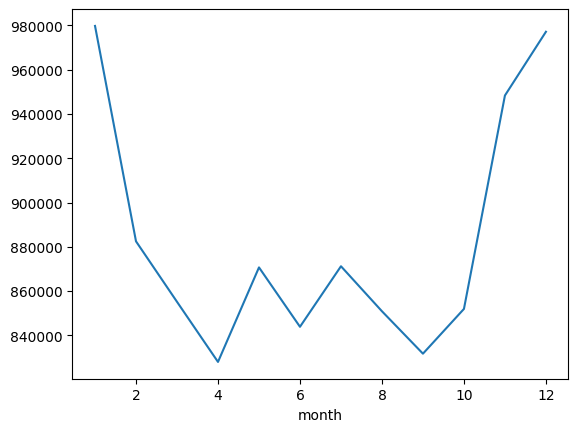

In [39]:
df.groupby('month')['units_sold'].sum().plot(kind="line")

<Axes: xlabel='month'>

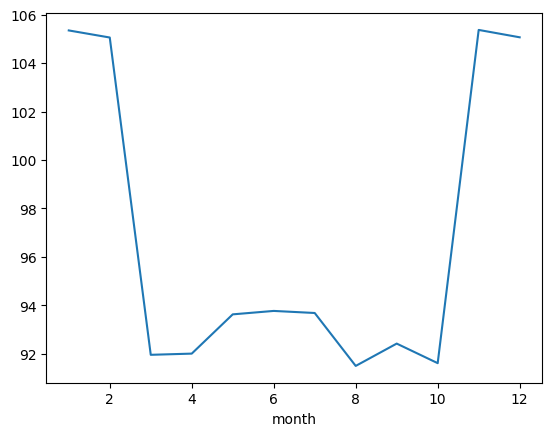

In [40]:
df.groupby('month')['units_sold'].mean().plot(kind="line")

<Axes: xlabel='month'>

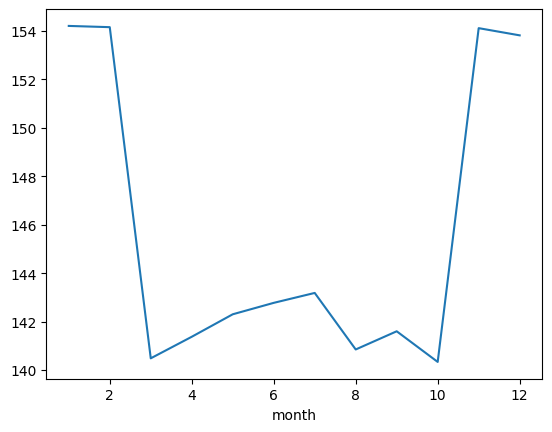

In [41]:
df.groupby('month')['inventory_level'].mean().plot(kind="line")

<Axes: xlabel='month'>

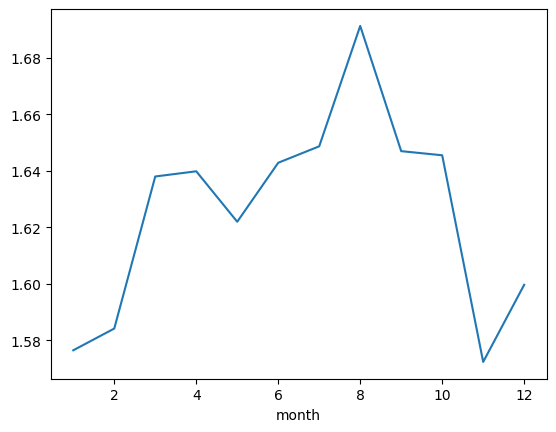

In [42]:
df.groupby('month')['days_of_stock'].mean().plot(kind='line')

In [43]:
limit = df['days_of_stock'].quantile(0.10)
print(limit)
df['at_risk'] = df['days_of_stock'] < limit
print(df['at_risk'].mean())

1.0775862068965518
0.09989041095890411


In [44]:
print(df.groupby('seasonality')['at_risk'].mean())
print(df.groupby('category')['at_risk'].mean())
print(df.groupby('store_id')['at_risk'].mean())

seasonality
Autumn    0.091884
Spring    0.097596
Summer    0.095761
Winter    0.110361
Name: at_risk, dtype: float64
category
Clothing       0.105056
Electronics    0.091747
Furniture      0.100776
Groceries      0.101781
Toys           0.099635
Name: at_risk, dtype: float64
store_id
S001    0.099361
S002    0.098767
S003    0.101826
S004    0.100274
S005    0.099224
Name: at_risk, dtype: float64


In [47]:
duckdb.sql("SELECT * FROM df LIMIT 5").df().shape

(5, 20)

In [48]:
duckdb.sql("""SELECT category, AVG(units_sold) AS mean_units_sold
FROM df
WHERE units_sold > 0
GROUP BY category
ORDER BY mean_units_sold DESC
""").df()


,category,mean_units_sold
0,Clothing,105.418847
1,Groceries,100.061720
2,Toys,93.140649
3,Furniture,93.027606
4,Electronics,88.336578


In [49]:
duckdb.sql("""
    SELECT
        date, store_id, product_id, inventory_level,
        LAG(inventory_level) OVER (
            PARTITION BY store_id, product_id
            ORDER BY date
        ) AS prev_inventory
    FROM df
    ORDER BY store_id, product_id, date
    LIMIT 10
""").df()

,date,store_id,product_id,inventory_level,prev_inventory
0,2022-01-01,S001,P0016,189,<NA>
1,2022-01-02,S001,P0016,84,189
2,2022-01-03,S001,P0016,184,84
3,2022-01-04,S001,P0016,93,184
4,2022-01-05,S001,P0016,186,93
5,2022-01-06,S001,P0016,111,186
6,2022-01-07,S001,P0016,130,111
7,2022-01-08,S001,P0016,180,130
8,2022-01-09,S001,P0016,162,180
9,2022-01-10,S001,P0016,127,162


In [50]:
duckdb.sql("""
    SELECT
        date, store_id, product_id, units_sold,
        AVG(units_sold) OVER (
            PARTITION BY store_id, product_id
            ORDER BY date
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS avg_7d
    FROM df
    ORDER BY store_id, product_id, date
    LIMIT 10
""").df()

,date,store_id,product_id,units_sold,avg_7d
0,2022-01-01,S001,P0016,127,127.000000
1,2022-01-02,S001,P0016,74,100.500000
2,2022-01-03,S001,P0016,183,128.000000
3,2022-01-04,S001,P0016,102,121.500000
4,2022-01-05,S001,P0016,128,122.800000
5,2022-01-06,S001,P0016,86,116.666667
6,2022-01-07,S001,P0016,55,107.857143
7,2022-01-08,S001,P0016,88,102.285714
8,2022-01-09,S001,P0016,168,115.714286
9,2022-01-10,S001,P0016,82,101.285714


In [51]:
duckdb.sql("""
    WITH base AS (
        SELECT
            date, store_id, product_id, inventory_level,
            AVG(units_sold) OVER (
                PARTITION BY store_id, product_id
                ORDER BY date
                ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING
            ) AS avg_prev_7d
        FROM df
    )
    SELECT
        date, store_id, product_id, inventory_level, avg_prev_7d,
        inventory_level < 1 * avg_prev_7d AS severe_risk
    FROM base
    WHERE avg_prev_7d IS NOT NULL
    ORDER BY store_id, product_id, date
    LIMIT 10
""").df()

,date,store_id,product_id,inventory_level,avg_prev_7d,severe_risk
0,2022-01-02,S001,P0016,84,127.000000,True
1,2022-01-03,S001,P0016,184,100.500000,False
2,2022-01-04,S001,P0016,93,128.000000,True
3,2022-01-05,S001,P0016,186,121.500000,False
4,2022-01-06,S001,P0016,111,122.800000,True
5,2022-01-07,S001,P0016,130,116.666667,False
6,2022-01-08,S001,P0016,180,107.857143,False
7,2022-01-09,S001,P0016,162,102.285714,False
8,2022-01-10,S001,P0016,127,115.714286,False
9,2022-01-11,S001,P0016,221,101.285714,False


In [52]:
duckdb.sql("""
    WITH base AS (
        SELECT inventory_level,
            AVG(units_sold) OVER (
                PARTITION BY store_id, product_id
                ORDER BY date
                ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING
            ) AS avg_prev_7d
        FROM df
    )
    SELECT AVG((inventory_level < 1 * avg_prev_7d)::INT) AS risk_share
    FROM base
    WHERE avg_prev_7d IS NOT NULL
""").df()

,risk_share
0,0.156946


In [53]:
duckdb.sql("""
    WITH base AS (
        SELECT
            category, seasonality, inventory_level,
            AVG(units_sold) OVER (
                PARTITION BY store_id, product_id
                ORDER BY date
                ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING
            ) AS avg_prev_7d
        FROM df
    ),
    flagged AS (
        SELECT
            category, seasonality,
            (inventory_level < 1 * avg_prev_7d)::INT AS severe_risk
        FROM base
        WHERE avg_prev_7d IS NOT NULL
    )
    SELECT category, seasonality, AVG(severe_risk) AS risk_share
    FROM flagged
    GROUP BY category, seasonality
    ORDER BY category, seasonality
""").df()

,category,seasonality,risk_share
0,Clothing,Autumn,0.149802
1,Clothing,Spring,0.164382
2,Clothing,Summer,0.153458
3,Clothing,Winter,0.195816
4,Electronics,Autumn,0.151766
5,Electronics,Spring,0.144262
6,Electronics,Summer,0.145652
7,Electronics,Winter,0.148536
8,Furniture,Autumn,0.155072
9,Furniture,Spring,0.148634


In [54]:
risk_table = duckdb.sql("""
    WITH base AS (
        SELECT
            category, seasonality, inventory_level,
            AVG(units_sold) OVER (
                PARTITION BY store_id, product_id
                ORDER BY date
                ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING
            ) AS avg_prev_7d
        FROM df
    ),
    flagged AS (
        SELECT
            category, seasonality,
            (inventory_level < 1 * avg_prev_7d)::INT AS severe_risk
        FROM base
        WHERE avg_prev_7d IS NOT NULL
    )
    SELECT category, seasonality, AVG(severe_risk) AS risk_share
    FROM flagged
    GROUP BY category, seasonality
""").df()

risk_grid = risk_table.pivot(
    index="category",
    columns="seasonality",
    values="risk_share"
)

risk_grid.shape

(5, 4)

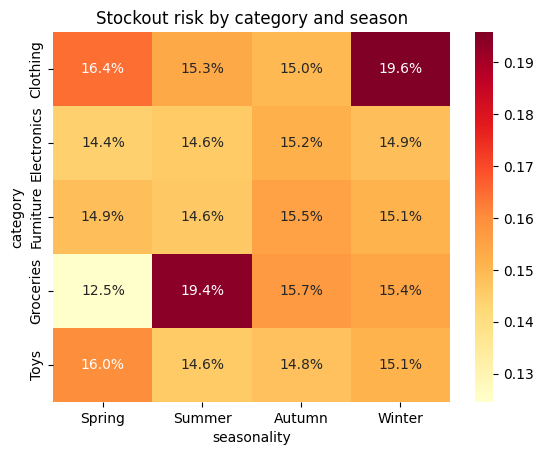

In [58]:
risk_grid = risk_grid[["Spring", "Summer", "Autumn", "Winter"]]
sns.heatmap(risk_grid, annot=True, fmt=".1%", cmap="YlOrRd")
plt.title("Stockout risk by category and season")
plt.show()

In [57]:
totals = df.groupby('category')[['units_ordered', 'units_sold']].sum()
totals['ratio'] = totals['units_ordered'] / totals['units_sold']
totals

,units_ordered,units_sold,ratio
category,,,
Clothing,4218952,4230880,0.997181
Electronics,2561155,2577043,0.993835
Furniture,2024812,2035351,0.994822
Groceries,725938,729550,0.995049
Toys,1014247,1018493,0.995831
